# A/B-тест стоимости Premium-подписки

Цель проекта — определить, был ли успешен эксперимент с изменением стоимости Premium-подписки.

Основная метрика — ARPU по всем продуктам. Тестовая группа сравнивается с объединёнными контрольными группами. Дополнительно анализируются конверсия в покупку, ARPPU, продуктовые конверсии и RPU.

Перед анализом зафиксированы правила:

- техническими дублями считаются одинаковые платежи одного пользователя за один продукт и одну сумму с интервалом не более двух секунд;
- повторные покупки с большим интервалом сохраняются;
- пользователи, попавшие в несколько групп, должны быть исключены;
- выбросы анализируются в трёх сценариях: полные данные, удаление по IQR и винзоризация p99;
- для множественных вторичных проверок применяется поправка Холма;
- эксперимент считается успешным только при статистически значимом и устойчивом росте ARPU.


## Загрузка данных

Данные загружаются напрямую через `pd.read_csv`.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from scipy.stats import chi2_contingency, ttest_ind, binomtest
from statsmodels.stats.proportion import proportions_ztest
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.multitest import multipletests

GROUPS = ['test', 'control_1', 'control_2']
PRODUCTS = ['premium_no_trial', 'trial_premium', 'coins', 'other_type']

In [2]:
users_test = pd.read_csv('Проект_3_users_test.csv', sep=';')
users_control_1 = pd.read_csv('Проект_3_users_control_1.csv', sep=';')
users_control_2 = pd.read_csv('Проект_3_users_control_2.csv', sep=';')

transactions_test = pd.read_csv('Проект_3_transactions_test.csv', sep=';')
transactions_control_1 = pd.read_csv('Проект_3_transactions_control_1.csv', sep=';')
transactions_control_2 = pd.read_csv('Проект_3_transactions_control_2.csv', sep=';')



In [3]:
users_test['group'] = 'test'
users_control_1['group'] = 'control_1'
users_control_2['group'] = 'control_2'

transactions_test['group'] = 'test'
transactions_control_1['group'] = 'control_1'
transactions_control_2['group'] = 'control_2'

users_df = pd.concat(
    [users_test, users_control_1, users_control_2],
    ignore_index=True
)

transactions_df = pd.concat(
    [transactions_test, transactions_control_1, transactions_control_2],
    ignore_index=True
)

print('Размер users_df:', users_df.shape)
print('Размер transactions_df:', transactions_df.shape)


Размер users_df: (12912, 14)
Размер transactions_df: (1608, 9)


В анализ объединены три пользовательские и три транзакционные таблицы. Для дальнейших сравнений экспериментальная группа хранится в столбце `group`.

## Проверка пропусков

Проверяем количество и долю пропусков. Транзакции без `uid` невозможно связать с пользователем, поэтому они не могут участвовать в расчёте метрик.

In [4]:
NaN_users_summary = (
    users_df
    .isna()
    .agg(['sum', 'mean'])
    .T
    .rename(columns={'sum': 'missing', 'mean': 'share_missing'})
    .sort_values('share_missing', ascending=False)
)

NaN_transactions_summary = (
    transactions_df
    .isna()
    .agg(['sum', 'mean'])
    .T
    .rename(columns={'sum': 'missing', 'mean': 'share_missing'})
    .sort_values('share_missing', ascending=False)
)

display(NaN_users_summary)
display(NaN_transactions_summary)

,missing,share_missing
coins,12742.0,0.986834
is_premium,12372.0,0.958178
was_premium,11657.0,0.902804
visit_days,4018.0,0.311183
age,0.0,0.000000
uid,0.0,0.000000
country,0.0,0.000000
attraction_coeff,0.0,0.000000
gender,0.0,0.000000
age_filter_start,0.0,0.000000


,missing,share_missing
uid,630.0,0.391791
country,630.0,0.391791
revenue,630.0,0.391791
from_page,630.0,0.391791
payment_id,630.0,0.391791
product_type,630.0,0.391791
joined_at,0.0,0.000000
paid_at,0.0,0.000000
group,0.0,0.000000


In [5]:
missing_uid = transactions_df['uid'].isna().sum()

transactions_df = (
    transactions_df
    .loc[transactions_df['uid'].notna()]
    .copy()
)

transactions_df['uid'] = transactions_df['uid'].astype('int64')

print('Удалено строк без uid:', missing_uid)
print('Размер transactions_df после очистки:', transactions_df.shape)


Удалено строк без uid: 630
Размер transactions_df после очистки: (978, 9)


**Вывод.** Обнаружено 630 технических строк без `uid`. Они исключены. Пропуски в пользовательских признаках не заполняются, поскольку эти поля не участвуют в расчёте основных денежных метрик.

## Проверка периода эксперимента

Период проверяется по `joined_at` из таблицы транзакций. Исторические транзакции исключаются только из транзакционного анализа. Соответствующие пользователи остаются в экспериментальной аудитории, чтобы ошибка одной строки не меняла состав рандомизированных групп.

In [6]:
transactions_df['joined_at_raw'] = transactions_df['joined_at'].astype(str)
transactions_df['paid_at_raw'] = transactions_df['paid_at'].astype(str)

transactions_df['joined_at'] = pd.to_datetime(
    transactions_df['joined_at_raw'],
    format='%Y-%m-%d %H:%M:%S',
    errors='coerce'
)

transactions_df['paid_at'] = pd.to_datetime(
    transactions_df['paid_at_raw'],
    format='%Y-%m-%d %H:%M:%S',
    errors='coerce'
)

joined_years = (
    transactions_df
    .assign(joined_year=transactions_df['joined_at'].dt.year)
    .groupby(['group', 'joined_year'], dropna=False)
    .size()
    .reset_index(name='transactions_count')
)

display(joined_years)

,group,joined_year,transactions_count
0,control_1,2015,3
1,control_1,2017,374
2,control_2,2017,328
3,test,2017,273


In [7]:
experiment_year = transactions_df['joined_at'].dt.year.mode()[0]

outside_window = transactions_df.loc[
    transactions_df['joined_at'].notna()
    & (transactions_df['joined_at'].dt.year != experiment_year)
].copy()

transactions_df = transactions_df.loc[
    transactions_df['joined_at'].isna()
    | (transactions_df['joined_at'].dt.year == experiment_year)
].copy()

print('Основной год эксперимента:', int(experiment_year))
print('Исключено исторических транзакций:', len(outside_window))
display(outside_window)


Основной год эксперимента: 2017
Исключено исторических транзакций: 3


,uid,country,joined_at,paid_at,revenue,payment_id,from_page,product_type,group,joined_at_raw,paid_at_raw
338,960936960,Russian Federation,2015-01-19 11:49:00,2016-12-14 17:30:00,26.0,0.0,refund_VP,other_type,control_1,2015-01-19 11:49:00,2016-12-14 17:30:00
374,960936960,Russian Federation,2015-01-19 11:49:00,2016-12-14 17:35:00,637.0,0.0,refung_AP,other_type,control_1,2015-01-19 11:49:00,2016-12-14 17:35:00
497,960936960,Russian Federation,2015-01-19 11:49:00,2016-12-14 16:16:00,143.0,0.0,refund_WP,other_type,control_1,2015-01-19 11:49:00,2016-12-14 16:16:00


**Вывод.** Основной год данных — 2017. Найдены три исторические транзакции с регистрацией в 2015 году. Исключены только эти transaction-строки; пользователи не удалялись из `users_df`.

## Проверка пользователей и сплитования

Проверяем дубли `uid` и пересечения пользователей между группами. Пользователя из нескольких групп пришлось бы исключить, поскольку его поведение нельзя однозначно связать с одним воздействием.

In [8]:
print('Дубли uid в users_df:', users_df['uid'].duplicated().sum())

test_users = set(users_df.loc[users_df['group'] == 'test', 'uid'])
control_1_users = set(users_df.loc[users_df['group'] == 'control_1', 'uid'])
control_2_users = set(users_df.loc[users_df['group'] == 'control_2', 'uid'])

intersection_test_control_1 = test_users & control_1_users
intersection_test_control_2 = test_users & control_2_users
intersection_control_1_control_2 = control_1_users & control_2_users

print('Пересечение test и control_1:', len(intersection_test_control_1))
print('Пересечение test и control_2:', len(intersection_test_control_2))
print('Пересечение control_1 и control_2:', len(intersection_control_1_control_2))

Дубли uid в users_df: 0
Пересечение test и control_1: 0
Пересечение test и control_2: 0
Пересечение control_1 и control_2: 0


In [9]:
intersection_users = (
    intersection_test_control_1
    | intersection_test_control_2
    | intersection_control_1_control_2
)

if len(intersection_users) > 0:
    users_df = users_df.loc[
        ~users_df['uid'].isin(intersection_users)
    ].copy()

    transactions_df = transactions_df.loc[
        ~transactions_df['uid'].isin(intersection_users)
    ].copy()

    print('Исключено пользователей:', len(intersection_users))
else:
    print('Пересечений между группами нет. Пользователи не исключались.')

Пересечений между группами нет. Пользователи не исключались.


**Вывод.** Пересечений `uid` между тестом и контрольными группами нет. Пользователи не исключались. Это подтверждает корректное сплитование экспериментальной аудитории.

## Проверка оплат раньше регистрации

Проверяем строки с `paid_at < joined_at` и гипотезу о перепутанных компонентах месяца и дня.

In [10]:
payment_before_join = transactions_df.loc[
    transactions_df['paid_at'] < transactions_df['joined_at']
].copy()

payment_before_join['gap_before_fix'] = (
    payment_before_join['paid_at']
    - payment_before_join['joined_at']
).dt.total_seconds() / 86400

print('Оплат раньше регистрации:', len(payment_before_join))

display(
    payment_before_join
    .groupby('group')
    .agg(
        transactions=('uid', 'size'),
        users=('uid', 'nunique'),
        min_gap=('gap_before_fix', 'min'),
        median_gap=('gap_before_fix', 'median'),
        max_gap=('gap_before_fix', 'max')
    )
    .reset_index()
)


Оплат раньше регистрации: 162


,group,transactions,users,min_gap,median_gap,max_gap
0,control_1,55,37,-288.234028,-170.751389,-5.197917
1,control_2,60,41,-292.116667,-195.236458,-4.125694
2,test,47,35,-287.908333,-197.290972,-10.217361


In [11]:
date_parts = payment_before_join['paid_at_raw'].str.extract(
    r'^(?P<year>\d{4})-(?P<month>\d{2})-(?P<day>\d{2}) (?P<time>.*)$'
)

paid_at_swapped = pd.to_datetime(
    date_parts['year'] + '-'
    + date_parts['day'] + '-'
    + date_parts['month'] + ' '
    + date_parts['time'],
    format='%Y-%m-%d %H:%M:%S',
    errors='coerce'
)

can_fix_date = (
    paid_at_swapped.notna()
    & (paid_at_swapped >= payment_before_join['joined_at'])
)

transactions_df['paid_at_corrected'] = transactions_df['paid_at']

transactions_df.loc[
    paid_at_swapped.index[can_fix_date],
    'paid_at_corrected'
] = paid_at_swapped.loc[can_fix_date]

payment_before_join['paid_at_corrected'] = paid_at_swapped
payment_before_join['gap_after_fix'] = (
    payment_before_join['paid_at_corrected']
    - payment_before_join['joined_at']
).dt.total_seconds() / 86400

print('Исправлено строк:', can_fix_date.sum())
print(
    'Ошибок после исправления:',
    (transactions_df['paid_at_corrected'] < transactions_df['joined_at']).sum()
)

display(payment_before_join.head())


Исправлено строк: 162
Ошибок после исправления: 0


,uid,country,joined_at,paid_at,revenue,payment_id,from_page,product_type,group,joined_at_raw,paid_at_raw,gap_before_fix,paid_at_corrected,gap_after_fix
11,891861048,Canada,2017-10-26 02:55:00,2017-10-11 19:00:00,3588.0,68.0,none,premium_no_trial,test,2017-10-26 02:55:00,2017-10-11 19:00:00,-14.329861,2017-11-10 19:00:00,15.670139
20,891806280,United States of America,2017-10-27 08:56:00,2017-03-11 10:57:00,8242.0,147.0,trial_vip_popup,trial_premium,test,2017-10-27 08:56:00,2017-03-11 10:57:00,-229.915972,2017-11-03 10:57:00,7.084028
24,891786216,Spain,2017-10-27 18:20:00,2017-03-11 20:20:00,12818.0,147.0,trial_vip_popup,trial_premium,test,2017-10-27 18:20:00,2017-03-11 20:20:00,-229.916667,2017-11-03 20:20:00,7.083333
25,892057347,France,2017-10-21 23:15:00,2017-08-11 01:56:00,1209.0,19.0,none,coins,test,2017-10-21 23:15:00,2017-08-11 01:56:00,-71.888194,2017-11-08 01:56:00,17.111806
36,891589239,Italy,2017-10-31 14:16:00,2017-09-11 15:44:00,6305.0,19.0,empty_likes,coins,test,2017-10-31 14:16:00,2017-09-11 15:44:00,-49.938889,2017-11-09 15:44:00,9.061111


**Вывод.** Найдено 162 платежа раньше регистрации. Во всех проблемных значениях третий компонент даты равен 11. После перестановки месяца и дня все платежи происходят через 1,88–25,87 дня после регистрации. Аномалия интерпретирована как смешанный формат даты, а не часовой пояс. Исправлены только однозначно восстанавливаемые строки.


## EDA

Смотрим размеры групп, исходную долю плательщиков и распределение выручки. `total_revenue` используется здесь только для знакомства с исходными данными. После дедубликации основная выручка будет пересчитана по транзакциям.

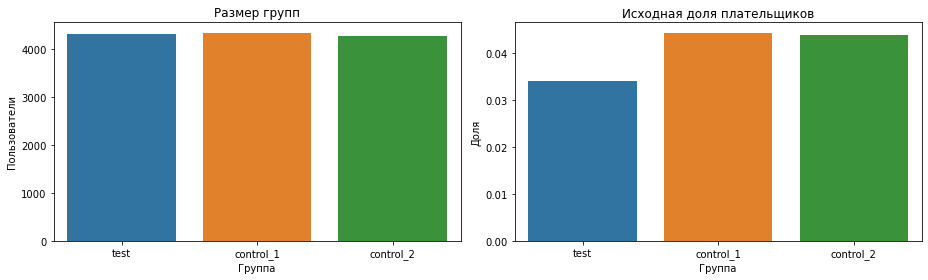

In [12]:
users_df['payer_raw'] = (users_df['total_revenue'] > 0).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.countplot(
    data=users_df,
    x='group',
    order=GROUPS,
    ax=axes[0]
)
axes[0].set_title('Размер групп')
axes[0].set_xlabel('Группа')
axes[0].set_ylabel('Пользователи')

payer_share = (
    users_df
    .groupby('group', as_index=False)['payer_raw']
    .mean()
)

sns.barplot(
    data=payer_share,
    x='group',
    y='payer_raw',
    order=GROUPS,
    ax=axes[1]
)
axes[1].set_title('Исходная доля плательщиков')
axes[1].set_xlabel('Группа')
axes[1].set_ylabel('Доля')

plt.tight_layout()
plt.show()

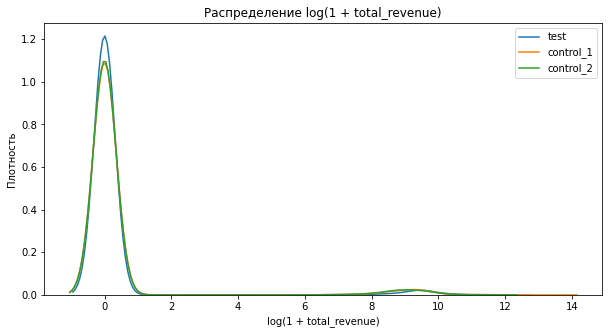

In [13]:
plt.figure(figsize=(10, 5))

for group in GROUPS:
    values = np.log1p(
        users_df.loc[
            users_df['group'] == group,
            'total_revenue'
        ]
    )

    sns.kdeplot(values, label=group)

plt.title('Распределение log(1 + total_revenue)')
plt.xlabel('log(1 + total_revenue)')
plt.ylabel('Плотность')
plt.legend()
plt.show()

**Вывод.** Размеры групп сопоставимы. В выручке много нулей и присутствует тяжёлый правый хвост. Поэтому денежные метрики дополнительно анализируются bootstrap-методом и в нескольких сценариях обработки выбросов.

## Дубликаты транзакций

Для одинаковых `uid`, `product_type` и `revenue` рассчитывается интервал до предыдущего платежа. Интервал от нуля до двух секунд считается признаком технического дубля. Повтор с большим интервалом считается реальной покупкой.

`payment_id` и `from_page` не входят в ключ дедубликации: при повторной отправке платёжного события служебные поля могут отличаться, хотя пользователь, продукт, сумма и время совпадают.

In [14]:
duplicate_key = ['group', 'uid', 'product_type', 'revenue']

transactions_sorted = (
    transactions_df
    .sort_values(
        duplicate_key
        + ['paid_at_corrected', 'payment_id', 'from_page']
    )
    .copy()
)

transactions_sorted['previous_payment_at'] = (
    transactions_sorted
    .groupby(duplicate_key)['paid_at_corrected']
    .shift(1)
)

transactions_sorted['seconds_from_previous_payment'] = (
    transactions_sorted['paid_at_corrected']
    - transactions_sorted['previous_payment_at']
).dt.total_seconds()

transactions_sorted['technical_duplicate'] = (
    transactions_sorted['seconds_from_previous_payment']
    .between(0, 2, inclusive='both')
)

transactions_sorted['real_repeat_purchase'] = (
    transactions_sorted['previous_payment_at'].notna()
    & (transactions_sorted['seconds_from_previous_payment'] > 2)
)


In [15]:
technical_duplicates = transactions_sorted.loc[
    transactions_sorted['technical_duplicate']
].copy()

real_repeat_purchases = transactions_sorted.loc[
    transactions_sorted['real_repeat_purchase']
].copy()

transactions_clean = transactions_sorted.loc[
    ~transactions_sorted['technical_duplicate']
].copy()

technical_duplicate_summary = (
    technical_duplicates
    .groupby(['group', 'product_type'])
    .agg(
        rows_removed=('uid', 'size'),
        users=('uid', 'nunique'),
        removed_revenue=('revenue', 'sum'),
        min_gap=('seconds_from_previous_payment', 'min'),
        max_gap=('seconds_from_previous_payment', 'max')
    )
    .reset_index()
)

display(technical_duplicate_summary)

print('Удалено технических строк:', len(technical_duplicates))
print('Удалённая выручка:', technical_duplicates['revenue'].sum())
print('Сохранено реальных повторных покупок:', len(real_repeat_purchases))


,group,product_type,rows_removed,users,removed_revenue,min_gap,max_gap
0,control_1,coins,16,10,95082.0,0.0,0.0
1,control_1,other_type,12,3,31473.0,0.0,0.0
2,control_1,premium_no_trial,2,2,12714.0,0.0,0.0
3,control_2,coins,12,10,17940.0,0.0,0.0
4,control_2,other_type,1,1,2353.0,0.0,0.0
5,control_2,premium_no_trial,1,1,4719.0,0.0,0.0
6,test,coins,5,5,5109.0,0.0,0.0
7,test,other_type,2,1,7566.0,0.0,0.0
8,test,premium_no_trial,1,1,9217.0,0.0,0.0


Удалено технических строк: 52
Удалённая выручка: 186173.0
Сохранено реальных повторных покупок: 135


In [16]:
display(
    real_repeat_purchases[
        [
            'group',
            'uid',
            'product_type',
            'revenue',
            'previous_payment_at',
            'paid_at_corrected',
            'seconds_from_previous_payment'
        ]
    ].head(20)
)


,group,uid,product_type,revenue,previous_payment_at,paid_at_corrected,seconds_from_previous_payment
291,control_1,891135642,coins,481.0,2017-10-11 17:49:00,2017-10-11 17:55:00,360.0
290,control_1,891254103,coins,1261.0,2017-10-11 20:47:00,2017-10-11 20:48:00,60.0
395,control_1,891296583,coins,1261.0,2017-11-11 08:29:00,2017-11-11 08:35:00,360.0
596,control_1,891299796,coins,728.0,2017-09-11 05:20:00,2017-09-11 05:21:00,60.0
292,control_1,891320823,coins,6305.0,2017-10-11 17:52:00,2017-12-11 18:52:00,5274000.0
335,control_1,891320823,other_type,3783.0,2017-05-11 23:23:00,2017-10-11 17:52:00,13199340.0
276,control_1,891367521,other_type,1456.0,2017-06-11 17:43:00,2017-06-11 19:15:00,5520.0
324,control_1,891707061,coins,1261.0,2017-11-04 00:30:00,2017-11-07 23:53:00,343380.0
296,control_1,891707061,coins,1261.0,2017-11-07 23:53:00,2017-11-10 00:04:00,173460.0
499,control_1,891707061,coins,1261.0,2017-11-10 00:04:00,2017-11-10 13:14:00,47400.0


**Вывод.** Удалены 52 мгновенные повторные строки на сумму 186 173. Интервал дублей равен 0 секунд. При этом 135 повторных платежей с интервалом больше двух секунд сохранены как реальные покупки. Такой подход сохраняет нормальные повторные покупки `coins` и не занижает ARPU.

## Выручка после очистки

После удаления технических дублей `users.total_revenue` содержит исходные начисления и больше не подходит для расчёта очищенного ARPU. Поэтому пользовательская выручка пересчитывается из `transactions_clean`.


In [17]:
uid_revenue = (
    transactions_clean
    .groupby(['group', 'uid'], as_index=False)['revenue']
    .sum()
    .rename(columns={'revenue': 'analysis_revenue'})
)

users_analysis = users_df.merge(
    uid_revenue,
    on=['group', 'uid'],
    how='left'
)

users_analysis['analysis_revenue'] = (
    users_analysis['analysis_revenue']
    .fillna(0)
)

users_analysis['payer'] = (
    users_analysis['analysis_revenue'] > 0
).astype(int)

In [18]:
revenue_check = users_analysis[
    ['group', 'uid', 'total_revenue', 'analysis_revenue']
].copy()

revenue_check['difference'] = (
    revenue_check['total_revenue']
    - revenue_check['analysis_revenue']
)

revenue_check_summary = (
    revenue_check
    .groupby('group')
    .agg(
        users=('uid', 'size'),
        mismatch_users=('difference', lambda x: (x != 0).sum()),
        users_total_revenue=('total_revenue', 'sum'),
        cleaned_transaction_revenue=('analysis_revenue', 'sum'),
        absolute_mismatch=('difference', lambda x: x.abs().sum())
    )
    .reset_index()
)

display(revenue_check_summary)


,group,users,mismatch_users,users_total_revenue,cleaned_transaction_revenue,absolute_mismatch
0,control_1,4340,16,2581267,2472236.0,169559.0
1,control_2,4264,12,1920438,1895426.0,25012.0
2,test,4308,7,2300818,2323009.0,65975.0


**Вывод.** Основные метрики далее рассчитываются по `analysis_revenue`. Разница с `total_revenue` ожидаема после исключения технических дублей. Единое правило очистки применила ко всем группам.

## Платёжные системы

Проверяем наличие отдельного идентификатора провайдера и возможность интерпретировать `payment_id` как платёжную систему.

In [25]:
payment_system_columns = [
    column
    for column in transactions_clean.columns
    if any(
        name in column.lower()
        for name in [
            'payment_system',
            'provider',
            'gateway',
            'payment_method',
            'acquirer'
        ]
    )
]

payment_id_check = (
    transactions_clean
    .groupby('payment_id', dropna=False)
    .agg(
        transactions=('uid', 'size'),
        users=('uid', 'nunique'),
        groups=('group', 'nunique'),
        products=('product_type', 'nunique')
    )
    .reset_index()
    .sort_values('transactions', ascending=False)
)

print('Поля платёжной системы:', payment_system_columns)
display(payment_id_check.head(20))

Поля платёжной системы: []


,payment_id,transactions,users,groups,products
6,147.0,421,408,3,2
1,19.0,266,136,3,2
2,67.0,99,75,3,1
5,146.0,86,85,3,1
3,68.0,46,41,3,2
0,0.0,4,4,3,1
4,127.0,1,1,1,1


**Вывод.** Явного поля платёжной системы нет. `payment_id` повторяется у разных пользователей, в разных группах и иногда у разных продуктов. Без внешнего справочника его нельзя надёжно интерпретировать как провайдера. Анализ оценивает всю тестовую группу, но не изолирует две новые платёжные системы.

## Продуктовые признаки

Для каждого пользователя рассчитываются выручка и признак покупки по каждому продукту. Пользователи без покупки получают нули.

In [26]:
buyers_df = (
    transactions_clean
    .groupby(['group', 'uid', 'product_type'])['revenue']
    .sum()
    .unstack(fill_value=0)
    .reset_index()
)

for product in PRODUCTS:
    if product not in buyers_df.columns:
        buyers_df[product] = 0

    buyers_df[product + '_buyer'] = (
        buyers_df[product] > 0
    ).astype(int)

buyers_df = buyers_df.rename(
    columns={
        product: 'revenue_' + product
        for product in PRODUCTS
    }
)

analysis_df = users_analysis.merge(
    buyers_df,
    on=['group', 'uid'],
    how='left'
)

for product in PRODUCTS:
    analysis_df['revenue_' + product] = (
        analysis_df['revenue_' + product]
        .fillna(0)
    )

    analysis_df[product + '_buyer'] = (
        analysis_df[product + '_buyer']
        .fillna(0)
        .astype(int)
    )


**Вывод.** Знаменателем продуктовых конверсий остаётся вся экспериментальная аудитория. Это позволяет сравнивать вероятность покупки каждого продукта между группами.

## Функции для статистических тестов

Для конверсий используется z-test пропорций. Для денежных метрик используется bootstrap разницы средних. Такой подход учитывает ненормальность и тяжёлый хвост выручки.

In [27]:
def conversion_test(data_1, data_2, column):
    count = [data_1[column].sum(), data_2[column].sum()]
    nobs = [len(data_1), len(data_2)]

    _, p_value = proportions_ztest(count, nobs)

    return (
        data_1[column].mean(),
        data_2[column].mean(),
        p_value
    )


def bootstrap_difference(
    values_1,
    values_2,
    n_boot=5000,
    seed=42,
    batch_size=500
):
    rng = np.random.default_rng(seed)

    values_1 = np.asarray(values_1, dtype=float)
    values_2 = np.asarray(values_2, dtype=float)

    all_differences = []

    for start in range(0, n_boot, batch_size):
        current_batch = min(batch_size, n_boot - start)

        sample_1 = rng.choice(
            values_1,
            size=(current_batch, len(values_1)),
            replace=True
        )

        sample_2 = rng.choice(
            values_2,
            size=(current_batch, len(values_2)),
            replace=True
        )

        differences = (
            sample_1.mean(axis=1)
            - sample_2.mean(axis=1)
        )

        all_differences.append(differences)

    all_differences = np.concatenate(all_differences)

    mean_1 = values_1.mean()
    mean_2 = values_2.mean()
    effect = mean_1 - mean_2
    uplift = effect / mean_2 if mean_2 != 0 else np.nan

    ci_left, ci_right = np.quantile(
        all_differences,
        [0.025, 0.975]
    )

    p_left = (
        (all_differences <= 0).sum() + 1
    ) / (len(all_differences) + 1)

    p_right = (
        (all_differences >= 0).sum() + 1
    ) / (len(all_differences) + 1)

    p_value = min(2 * min(p_left, p_right), 1)

    return {
        'test_value': mean_1,
        'control_value': mean_2,
        'absolute_effect': effect,
        'relative_uplift': uplift,
        'ci_left': ci_left,
        'ci_right': ci_right,
        'p_value': p_value
    }


## A/A-тест

Проверяем размеры контрольных групп, пользовательские признаки и основные метрики. A/A-тест используется как диагностика качества сплитования.

In [28]:
control_1 = analysis_df.loc[
    analysis_df['group'] == 'control_1'
].copy()

control_2 = analysis_df.loc[
    analysis_df['group'] == 'control_2'
].copy()

print('Размеры control_1 и control_2:', len(control_1), len(control_2))
print(
    'Binomial p-value:',
    binomtest(
        len(control_1),
        len(control_1) + len(control_2),
        0.5
    ).pvalue
)


Размеры control_1 и control_2: 4340 4264
Binomial p-value: 0.41877111666537153


In [29]:
for column in ['gender', 'country']:
    table = pd.crosstab(
        users_df.loc[
            users_df['group'].isin(['control_1', 'control_2']),
            'group'
        ],
        users_df.loc[
            users_df['group'].isin(['control_1', 'control_2']),
            column
        ]
    )

    chi2, p_value, _, _ = chi2_contingency(table)
    cramer_v = np.sqrt(chi2 / table.values.sum())

    print(
        column,
        'p_value =', round(p_value, 4),
        'Cramer_V =', round(cramer_v, 4)
    )

for column in [
    'age',
    'attraction_coeff',
    'age_filter_start',
    'age_filter_end'
]:
    values_1 = control_1[column].dropna()
    values_2 = control_2[column].dropna()

    p_value = ttest_ind(
        values_1,
        values_2,
        equal_var=False
    ).pvalue

    pooled_sd = np.sqrt(
        (values_1.var(ddof=1) + values_2.var(ddof=1)) / 2
    )

    smd = (values_1.mean() - values_2.mean()) / pooled_sd

    print(
        column,
        'p_value =', round(p_value, 4),
        'SMD =', round(smd, 4)
    )


gender p_value = 0.4194 Cramer_V = 0.0087
country p_value = 0.2791 Cramer_V = 0.0854
age p_value = 0.8233 SMD = 0.0048
attraction_coeff p_value = 0.3972 SMD = -0.0183
age_filter_start p_value = 0.4322 SMD = -0.0169
age_filter_end p_value = 0.2931 SMD = -0.0227


In [30]:
print(
    'Payer CR:',
    conversion_test(control_1, control_2, 'payer')
)

print(
    'ARPU:',
    bootstrap_difference(
        control_1['analysis_revenue'],
        control_2['analysis_revenue']
    )
)

print(
    'ARPPU:',
    bootstrap_difference(
        control_1.loc[
            control_1['payer'] == 1,
            'analysis_revenue'
        ],
        control_2.loc[
            control_2['payer'] == 1,
            'analysis_revenue'
        ]
    )
)


Payer CR: (0.04423963133640553, 0.04385553470919325, 0.9308246292783225)
ARPU: {'test_value': 569.6396313364055, 'control_value': 444.5182926829268, 'absolute_effect': 125.12133865347869, 'relative_uplift': 0.28147624228982465, 'ci_left': -67.98575425705296, 'ci_right': 369.893127669439, 'p_value': 0.24875024995001}
ARPPU: {'test_value': 12876.229166666666, 'control_value': 10135.967914438503, 'absolute_effect': 2740.2612522281634, 'relative_uplift': 0.27035022953503146, 'ci_left': -773.0566824030755, 'ci_right': 8042.999234068624, 'p_value': 0.1847630473905219}


**Вывод.** Статистически значимых различий по проверенным пользовательским признакам и основным результатным метрикам между контрольными группами не обнаружено. Явных признаков некорректного сплитования нет. Контрольные группы объединяются в соответствии с заранее заданным планом анализа.

## Основные метрики A/B-теста


In [31]:
test_df = analysis_df.loc[
    analysis_df['group'] == 'test'
].copy()

control_df = analysis_df.loc[
    analysis_df['group'].isin(['control_1', 'control_2'])
].copy()

main_metrics = (
    analysis_df
    .groupby('group')
    .agg(
        users=('uid', 'size'),
        payers=('payer', 'sum'),
        payer_CR=('payer', 'mean'),
        revenue=('analysis_revenue', 'sum'),
        ARPU=('analysis_revenue', 'mean'),
        ARPPU=(
            'analysis_revenue',
            lambda x: x[x > 0].mean()
        )
    )
    .reset_index()
)

display(main_metrics)

,group,users,payers,payer_CR,revenue,ARPU,ARPPU
0,control_1,4340,192,0.044240,2472236.0,569.639631,12876.229167
1,control_2,4264,187,0.043856,1895426.0,444.518293,10135.967914
2,test,4308,146,0.033890,2323009.0,539.231430,15911.020548


In [32]:
arpu_result = bootstrap_difference(
    test_df['analysis_revenue'],
    control_df['analysis_revenue']
)

arppu_result = bootstrap_difference(
    test_df.loc[
        test_df['payer'] == 1,
        'analysis_revenue'
    ],
    control_df.loc[
        control_df['payer'] == 1,
        'analysis_revenue'
    ]
)

conversion_results = []

for column in (
    ['payer']
    + [product + '_buyer' for product in PRODUCTS]
):
    test_value, control_value, p_value = conversion_test(
        test_df,
        control_df,
        column
    )

    conversion_results.append({
        'metric': column,
        'test_value': test_value,
        'control_value': control_value,
        'absolute_effect': test_value - control_value,
        'relative_uplift': (
            (test_value - control_value) / control_value
        ),
        'p_value': p_value
    })

conversion_results = pd.DataFrame(conversion_results)

reject, p_holm, _, _ = multipletests(
    conversion_results['p_value'],
    alpha=0.05,
    method='holm'
)

conversion_results['p_holm'] = p_holm
conversion_results['significant_holm'] = reject

display(pd.DataFrame([
    {'metric': 'ARPU', **arpu_result},
    {'metric': 'ARPPU', **arppu_result}
]))

display(conversion_results)

,metric,test_value,control_value,absolute_effect,relative_uplift,ci_left,ci_right,p_value
0,ARPU,539.231430,507.631567,31.599863,0.062250,-142.147115,201.717121,0.710658
1,ARPPU,15911.020548,11524.174142,4386.846405,0.380665,645.961822,8048.041822,0.022795


,metric,test_value,control_value,absolute_effect,relative_uplift,p_value,p_holm,significant_holm
0,payer,0.033890,0.044049,-0.010159,-0.230624,0.005853,0.023411,True
1,premium_no_trial_buyer,0.015552,0.023361,-0.007809,-0.334262,0.003339,0.016696,True
2,trial_premium_buyer,0.014160,0.013947,0.000213,0.015251,0.922777,0.922777,False
3,coins_buyer,0.012071,0.015574,-0.003504,-0.224962,0.115161,0.230321,False
4,other_type_buyer,0.004410,0.007206,-0.002796,-0.387950,0.057821,0.173463,False


**Вывод.** После удаления технических дублей ARPU теста равен 539,23, а ARPU объединённого контроля — 507,63. Uplift составляет 6,22%, но 95% доверительный интервал разницы от -147,32 до 203,18 включает ноль. Статистически значимого роста основной метрики нет.

Payer CR снизилась с 4,40% до 3,39%. Относительное снижение составляет 23,06% и остаётся значимым после поправки Холма. ARPPU вырос с 11 524,17 до 15 911,02, но рост выручки на плательщика не обеспечил статистически надёжный рост ARPU.


### Почему применяется поправка Холма

Одновременно проверяются общая конверсия и конверсии в несколько продуктов. При множественных тестах увеличивается вероятность случайно получить хотя бы один ложноположительный результат. Метод Холма контролирует семейную вероятность ошибки первого рода и менее консервативен, чем обычная поправка Бонферрони.

## Sensitivity analysis выбросов

Рассматриваются три сценария. Ни один вариант не объявляется единственно правильным: задача — определить, зависит ли бизнес-вывод от нескольких крупных плательщиков.

In [33]:
control_payers = control_df.loc[
    control_df['analysis_revenue'] > 0,
    'analysis_revenue'
]

q1 = control_payers.quantile(0.25)
q3 = control_payers.quantile(0.75)
iqr_limit = q3 + 1.5 * (q3 - q1)

filtered_df = analysis_df.loc[
    analysis_df['analysis_revenue'] <= iqr_limit
].copy()

filtered_result = bootstrap_difference(
    filtered_df.loc[
        filtered_df['group'] == 'test',
        'analysis_revenue'
    ],
    filtered_df.loc[
        filtered_df['group'].isin(['control_1', 'control_2']),
        'analysis_revenue'
    ]
)

p99 = analysis_df.loc[
    analysis_df['analysis_revenue'] > 0,
    'analysis_revenue'
].quantile(0.99)

analysis_df['revenue_winsor'] = (
    analysis_df['analysis_revenue']
    .clip(upper=p99)
)

winsor_result = bootstrap_difference(
    analysis_df.loc[
        analysis_df['group'] == 'test',
        'revenue_winsor'
    ],
    analysis_df.loc[
        analysis_df['group'].isin(['control_1', 'control_2']),
        'revenue_winsor'
    ]
)

scenario_results = pd.DataFrame([
    {'scenario': 'Полные очищенные данные', **arpu_result},
    {'scenario': 'Без контроль-IQR выбросов', **filtered_result},
    {'scenario': 'Winsorization p99', **winsor_result}
])

display(scenario_results)

,scenario,test_value,control_value,absolute_effect,relative_uplift,ci_left,ci_right,p_value
0,Полные очищенные данные,539.231430,507.631567,31.599863,0.062250,-142.147115,201.717121,0.710658
1,Без контроль-IQR выбросов,318.737934,372.499592,-53.761658,-0.144327,-128.454273,18.365658,0.136773
2,Winsorization p99,512.887419,468.858205,44.029213,0.093907,-82.971951,177.624648,0.509898


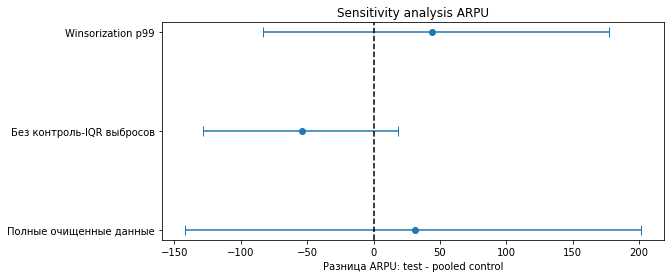

In [34]:
plt.figure(figsize=(9, 4))

y = np.arange(len(scenario_results))

plt.errorbar(
    scenario_results['absolute_effect'],
    y,
    xerr=[
        scenario_results['absolute_effect']
        - scenario_results['ci_left'],
        scenario_results['ci_right']
        - scenario_results['absolute_effect']
    ],
    fmt='o',
    capsize=5
)

plt.axvline(0, color='black', linestyle='--')
plt.yticks(y, scenario_results['scenario'])
plt.xlabel('Разница ARPU: test - pooled control')
plt.title('Sensitivity analysis ARPU')
plt.show()


**Вывод.** На полных очищенных данных эффект ARPU равен +31,60. После удаления наблюдений выше control-IQR эффект становится отрицательным и равен -53,76. После винзоризации p99 эффект равен +44,03. Во всех сценариях доверительный интервал включает ноль.

Статистически значимого роста ARPU нет, а знак эффекта зависит от способа обработки крупных плательщиков. Следовательно, результат неустойчив и полный rollout является рискованным.

## Проверка каннибализации

Сравниваем конверсии и RPU отдельных продуктов. Решение принимается по совокупному ARPU, а не по росту одного продукта.

In [35]:
product_metrics = []

for group in GROUPS:
    part = analysis_df.loc[
        analysis_df['group'] == group
    ]

    for product in PRODUCTS:
        product_metrics.append({
            'group': group,
            'product': product,
            'users': len(part),
            'buyers': part[product + '_buyer'].sum(),
            'conversion': part[product + '_buyer'].mean(),
            'revenue': part['revenue_' + product].sum(),
            'RPU': part['revenue_' + product].mean(),
            'RPPU': part.loc[
                part['revenue_' + product] > 0,
                'revenue_' + product
            ].mean()
        })

product_metrics = pd.DataFrame(product_metrics)
display(product_metrics)


,group,product,users,buyers,conversion,revenue,RPU,RPPU
0,test,premium_no_trial,4308,67,0.015552,801489.0,186.046657,11962.522388
1,test,trial_premium,4308,61,0.014160,800202.0,185.747911,13118.065574
2,test,coins,4308,52,0.012071,561067.0,130.238394,10789.750000
3,test,other_type,4308,19,0.004410,160251.0,37.198468,8434.263158
4,control_1,premium_no_trial,4340,99,0.022811,766545.0,176.623272,7742.878788
5,control_1,trial_premium,4340,67,0.015438,772720.0,178.046083,11533.134328
6,control_1,coins,4340,65,0.014977,776828.0,178.992627,11951.200000
7,control_1,other_type,4340,29,0.006682,156143.0,35.977650,5384.241379
8,control_2,premium_no_trial,4264,102,0.023921,740090.0,173.567073,7255.784314
9,control_2,trial_premium,4264,53,0.012430,643981.0,151.027439,12150.584906


In [36]:
product_effects = []

for number, product in enumerate(PRODUCTS):
    result = bootstrap_difference(
        test_df['revenue_' + product],
        control_df['revenue_' + product],
        seed=42 + number
    )

    product_effects.append({
        'product': product,
        **result
    })

product_effects = pd.DataFrame(product_effects)

reject, p_holm, _, _ = multipletests(
    product_effects['p_value'],
    alpha=0.05,
    method='holm'
)

product_effects['p_holm'] = p_holm
product_effects['significant_holm'] = reject

display(product_effects)


,product,test_value,control_value,absolute_effect,relative_uplift,ci_left,ci_right,p_value,p_holm,significant_holm
0,premium_no_trial,186.046657,175.108670,10.937987,0.062464,-71.481570,112.448246,0.850630,1.0,False
1,trial_premium,185.747911,164.656090,21.091821,0.128096,-34.815979,76.179905,0.465907,1.0,False
2,coins,130.238394,135.029870,-4.791476,-0.035485,-107.212079,82.223806,0.993001,1.0,False
3,other_type,37.198468,32.836936,4.361532,0.132824,-24.271838,41.942129,0.881424,1.0,False


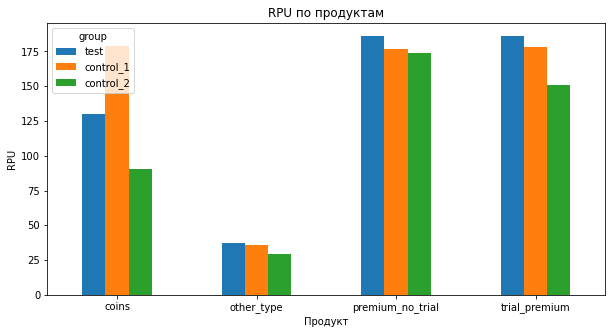

In [37]:
plot_rpu = (
    product_metrics
    .pivot(
        index='product',
        columns='group',
        values='RPU'
    )[GROUPS]
)

plot_rpu.plot(kind='bar', figsize=(10, 5))
plt.title('RPU по продуктам')
plt.xlabel('Продукт')
plt.ylabel('RPU')
plt.xticks(rotation=0)
plt.show()

**Вывод.** После поправки Холма ни один продуктовый RPU-эффект не является значимым. Конверсия в `premium_no_trial` снизилась с 2,34% до 1,56% и остаётся значимой после коррекции. Конверсия в `trial_premium` существенно не изменилась. Убедительных доказательств перетока выручки в trial, coins или другие продукты нет.

## Анализ по странам

Страновой анализ эксплораторный. Рассмотрела только страны с достаточным числом пользователей, а для p-values применяется поправка Холма.

In [38]:
country_results = []

for country in sorted(analysis_df['country'].dropna().unique()):
    country_test = analysis_df.loc[
        (analysis_df['group'] == 'test')
        & (analysis_df['country'] == country)
    ]

    country_control = analysis_df.loc[
        analysis_df['group'].isin(['control_1', 'control_2'])
        & (analysis_df['country'] == country)
    ]

    if len(country_test) >= 50 and len(country_control) >= 100:
        result = bootstrap_difference(
            country_test['analysis_revenue'],
            country_control['analysis_revenue'],
            n_boot=3000
        )

        country_results.append({
            'country': country,
            'n_test': len(country_test),
            'n_control': len(country_control),
            'payers_test': country_test['payer'].sum(),
            'payers_control': country_control['payer'].sum(),
            **result
        })

country_results = pd.DataFrame(country_results)

if not country_results.empty:
    reject, p_holm, _, _ = multipletests(
        country_results['p_value'],
        alpha=0.05,
        method='holm'
    )

    country_results['p_holm'] = p_holm
    country_results['significant_holm'] = reject

    country_results = country_results.sort_values(
        'absolute_effect',
        ascending=False
    )

display(country_results)

,country,n_test,n_control,payers_test,payers_control,test_value,control_value,absolute_effect,relative_uplift,ci_left,ci_right,p_value,p_holm,significant_holm
10,Spain,301,652,15,21,948.265781,449.138037,499.127744,1.111301,-247.860227,1607.800009,0.283905,1.00000,False
11,United Arab Emirates,226,418,9,12,905.168142,460.971292,444.196850,0.963611,-495.242898,1858.002253,0.503166,1.00000,False
5,France,359,746,13,41,829.247911,432.293566,396.954345,0.918252,-99.668774,992.539249,0.141953,1.00000,False
6,Germany,209,390,7,10,459.789474,244.633333,215.156140,0.879505,-217.731272,763.857532,0.396534,1.00000,False
0,Argentina,396,786,7,22,474.795455,334.840967,139.954488,0.417973,-297.572790,717.100728,0.661113,1.00000,False
13,United States of America,1450,2957,52,124,490.593103,437.181603,53.411500,0.122172,-142.635525,277.472378,0.593802,1.00000,False
3,Canada,137,268,6,13,463.255474,457.425373,5.830101,0.012745,-503.104222,554.991425,0.972343,1.00000,False
7,Israel,106,187,5,20,882.528302,958.663102,-76.134800,-0.079418,-950.153552,889.066406,0.807064,1.00000,False
4,Chile,272,573,4,21,257.132353,359.825480,-102.693127,-0.285397,-401.492004,255.923491,0.501166,1.00000,False
2,Belgium,92,198,4,14,681.369565,787.090909,-105.721344,-0.134319,-854.517240,736.805295,0.785738,1.00000,False


**Вывод.** После поправки Холма значимых страновых ARPU-эффектов нет. Доверительные интервалы широкие из-за малого числа плательщиков, поэтому страновые результаты не используются как основание для роллаута.


## Итоговый вывод

Эксперимент нельзя признать коммерчески успешным.

После удаления технических дублей ARPU теста выше контроля на 6,22%, однако доверительный интервал включает 0. Статистически значимый рост основной метрики не подтверждён.

**Payer CR снизилась на 23,06%, а ARPPU вырос на 38,07%. Рост выручки на плательщика не обеспечил надёжного роста совокупной выручки на пользователя.**

**Sensitivity analysis показывает зависимость результата от крупных плательщиков.** На полных данных и после винзоризации эффект положительный, а после IQR-очистки — отрицательный. Во всех сценарии рост ARPU не является статистически значимым.

**Продуктовый анализ не подтверждает компенсирующий переход в другие продукты.** Значимых страновых эффектов после поправки Холма также нет.

**В данных отсутствует идентификатор платёжного провайдера, поэтому нельзя отдельно оценить влияние двух новых платёжных систем.**

**Бизнес-решение — продлить эксперимент и не выполнять полный rollout новой цены.** Перед повторным тестом желательно добавить явное поле платёжной системы и уникальный идентификатор транзакции, увеличить выборку и заранее определить минимально значимый uplift ARPU.